# 23CSE301 Machine Learning — Capstone, Review 2
## Clustering Track — K-Means & Agglomerative Hierarchical Clustering

**Team:** ASV_INTELLIGENCE  
**Members:** Ashwin Kumar Srinivasan (CB.SC.U4CSE24607), Salla Sai Sumallik (CB.SC.U4CSE24647), Tallada Vamshidhar (CB.SC.U4CSE24660)  
**Track owner:** Salla Sai Sumallik

**Dataset:** Mall Customer Segmentation (Kaggle `vjchoudhary7/customer-segmentation-tutorial-in-python`) — 200 customers with Age, Annual Income (k$), Spending Score (1–100) and Gender.

**Goal:** discover natural customer segments for targeted marketing. Clustering is **unsupervised** and this dataset has **no ground-truth label**, so quality is judged with internal metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) and by interpreting the cluster profiles. `Gender` is excluded from fitting and used only afterwards to describe the clusters.

In [1]:
import warnings, time, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 1. Load data & scale
Distance-based clustering is scale-sensitive, so features are standardised. There is no train/test split in clustering, so the scaler is fitted on the feature matrix once.

In [2]:
# ---- DATASET CONFIG ----
# Mall Customer Segmentation (Kaggle: vjchoudhary7/customer-segmentation-tutorial-in-python) -> unsupervised, NO label column
DATA_PATH = "../data/Mall_Customers.csv"
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"Annual Income (k$)": "Annual_Income_k", "Spending Score (1-100)": "Spending_Score"})
df = df.drop(columns=["CustomerID"])               # identifier, carries no information
print("Loaded:", DATA_PATH, "| shape:", df.shape)
display(df.head())

Loaded: ../data/Mall_Customers.csv | shape: (200, 4)


,Gender,Age,Annual_Income_k,Spending_Score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [3]:
from sklearn.preprocessing import StandardScaler
FEATURES = ["Age", "Annual_Income_k", "Spending_Score"]       # numeric behavioural features used for clustering
gender = df["Gender"].values                                    # kept aside for post-hoc profiling only — NOT used for fitting
X = df[FEATURES]
Xs = StandardScaler().fit_transform(X)
print("Feature matrix:", Xs.shape, "| missing:", int(X.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
display(X.describe().T.round(2))

Feature matrix: (200, 3) | missing: 0 | duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual_Income_k,200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending_Score,200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


## 2. K-Means — choosing k (Elbow curve + silhouette)

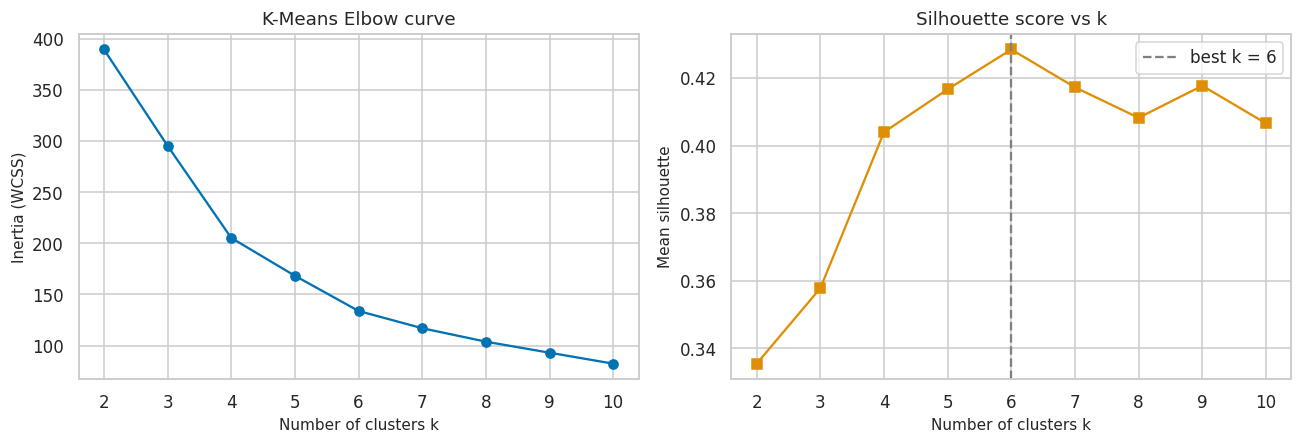

k with max silhouette: 6


In [4]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score

ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_title("K-Means Elbow curve"); axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(list(ks), sil, "s-", color=sns.color_palette("colorblind")[1]); axes[1].set_title("Silhouette score vs k"); axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Mean silhouette")
K = list(ks)[int(np.argmax(sil))]
axes[1].axvline(K, ls="--", color="grey", label=f"best k = {K}"); axes[1].legend()
plt.tight_layout(); plt.savefig("../figures/clu_elbow_silhouette.png", bbox_inches="tight"); plt.show()
print("k with max silhouette:", K)

> ✏️ **DRAFT observation — verify against your plots and rewrite in your own words (course rule 7.5: interpretation must be original).**

Inertia drops steeply until k≈5–6 (389 → 295 → 205 → 168 → 134) and then flattens (117 at k=7), so the elbow lies around 5–6. The silhouette score peaks at **k=6 (≈ 0.428)**, with k=5 (0.417) and k=7 (0.417) almost as good. We use k=6 (max silhouette); k=5 is a defensible alternative. A silhouette ≈ 0.43 indicates reasonably well-separated, moderately compact clusters.

## 3. Agglomerative Hierarchical Clustering — dendrogram & linkage comparison

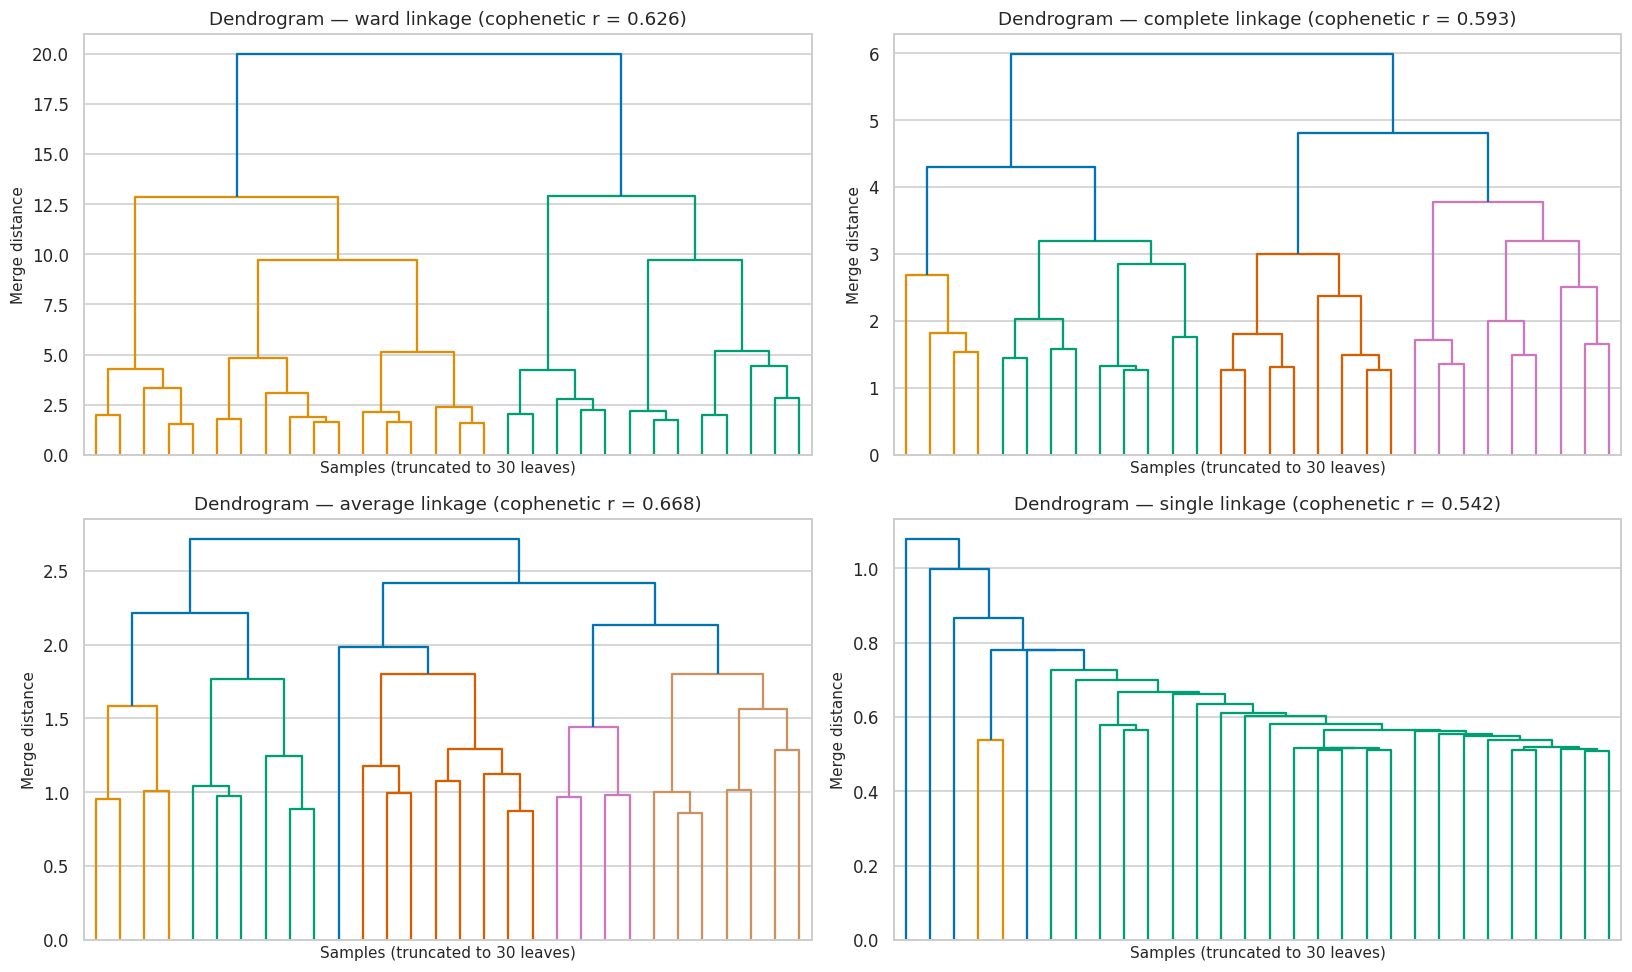

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
d = pdist(Xs)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, method in zip(axes.ravel(), ["ward", "complete", "average", "single"]):
    Z = linkage(Xs, method=method); c, _ = cophenet(Z, d)
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, no_labels=True, color_threshold=0.7 * Z[-1, 2])
    ax.set_title(f"Dendrogram — {method} linkage (cophenetic r = {c:.3f})"); ax.set_xlabel("Samples (truncated to 30 leaves)"); ax.set_ylabel("Merge distance")
plt.tight_layout(); plt.savefig("../figures/clu_dendrograms.png", bbox_inches="tight"); plt.show()

In [6]:
# Compare linkage strategies at the same k (internal metrics only — no labels)
link_rows = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(Xs)
    link_rows.append({"Linkage": link, "Silhouette": silhouette_score(Xs, lab), "Davies-Bouldin": davies_bouldin_score(Xs, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(Xs, lab), "Cluster sizes": np.bincount(lab).tolist()})
link_df = pd.DataFrame(link_rows).set_index("Linkage"); display(link_df.round(4))
best_link = link_df["Silhouette"].idxmax(); print("Best linkage by silhouette:", best_link)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Linkage,,,,
ward,0.4201,0.8521,127.9865,"[45, 45, 39, 28, 22, 21]"
complete,0.3746,1.0005,109.4154,"[35, 39, 57, 16, 21, 32]"
average,0.3896,0.8646,102.0370,"[20, 52, 31, 39, 54, 4]"
single,-0.0428,0.6370,3.4751,"[193, 2, 2, 1, 1, 1]"


Best linkage by silhouette: ward


> ✏️ **DRAFT observation — verify against your plots and rewrite in your own words (course rule 7.5: interpretation must be original).**

**Ward** gives the best silhouette (≈ 0.420) and Calinski-Harabasz (≈ 128) with balanced sizes (45/45/39/28/22/21). Single linkage chains: one cluster of 193 points and five tiny ones (silhouette < 0). Note the trap: single linkage has the *lowest* (best-looking) Davies-Bouldin (≈ 0.64) even though the clustering is useless, because tiny outlier clusters have tiny scatter. Always read the three metrics together.

## 4. Fit final models & evaluate with all three internal metrics
Silhouette ↑ better · Davies-Bouldin ↓ better · Calinski-Harabasz ↑ better.

In [7]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xs)
agg = AgglomerativeClustering(n_clusters=K, linkage=best_link).fit(Xs)
labels = {"K-Means": kmeans.labels_, f"Agglomerative ({best_link})": agg.labels_}
rows = []
for name, lab in labels.items():
    rows.append({"Algorithm": name, "k": len(np.unique(lab)), "Silhouette (↑)": silhouette_score(Xs, lab),
                 "Davies-Bouldin (↓)": davies_bouldin_score(Xs, lab), "Calinski-Harabasz (↑)": calinski_harabasz_score(Xs, lab),
                 "Cluster sizes": np.bincount(lab).tolist()})
clu_df = pd.DataFrame(rows).set_index("Algorithm"); display(clu_df.round(4)); clu_df.round(4).to_csv("../figures/clustering_metrics.csv")

,k,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Cluster sizes
Algorithm,,,,,
K-Means,6,0.4284,0.8254,135.1021,"[45, 39, 33, 39, 23, 21]"
Agglomerative (ward),6,0.4201,0.8521,127.9865,"[45, 45, 39, 28, 22, 21]"


> ✏️ **DRAFT observation — verify against your plots and rewrite in your own words (course rule 7.5: interpretation must be original).**

K-Means is slightly ahead of Ward on all three internal metrics (Silhouette 0.428 vs 0.420, Davies-Bouldin 0.825 vs 0.852 — lower is better, Calinski-Harabasz 135.1 vs 128.0). The differences are small; K-Means optimises within-cluster variance directly, which is what these metrics reward. Both produce 6 clusters of similar size.

## 5. Cluster visualisation — PCA (2 components) for every algorithm

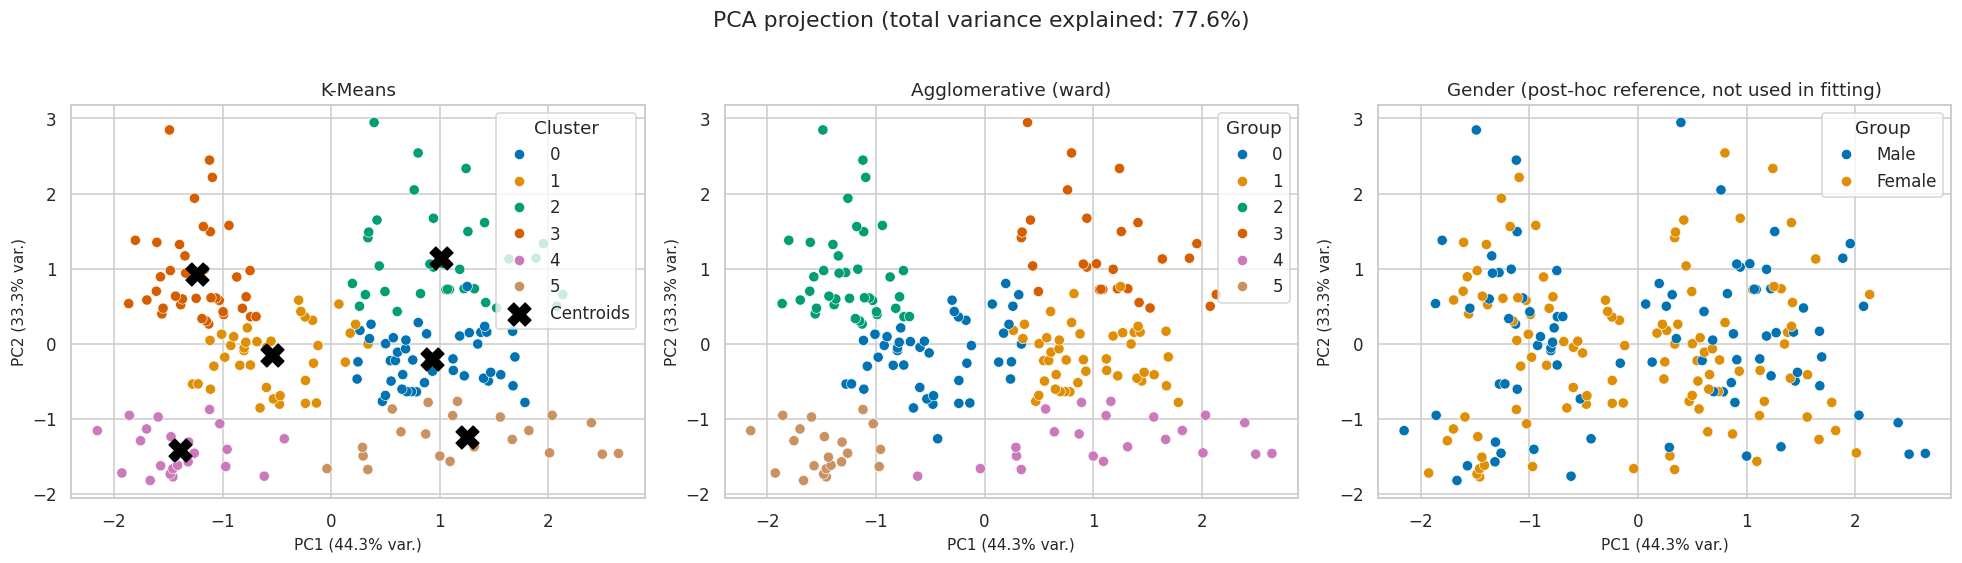

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE); P = pca.fit_transform(Xs)
ev = pca.explained_variance_ratio_ * 100
panels = {**labels, "Gender (post-hoc reference, not used in fitting)": gender}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, lab) in zip(axes, panels.items()):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=lab, palette="colorblind", s=45, ax=ax, edgecolor="white", linewidth=0.4, legend="full")
    ax.set_title(name); ax.set_xlabel(f"PC1 ({ev[0]:.1f}% var.)"); ax.set_ylabel(f"PC2 ({ev[1]:.1f}% var.)"); ax.legend(title="Group")
if hasattr(kmeans, "cluster_centers_"):
    cp = pca.transform(kmeans.cluster_centers_); axes[0].scatter(cp[:, 0], cp[:, 1], marker="X", s=220, c="black", label="Centroids")
    axes[0].legend(title="Cluster")
fig.suptitle(f"PCA projection (total variance explained: {ev.sum():.1f}%)", y=1.02)
plt.tight_layout(); plt.savefig("../figures/clu_pca.png", bbox_inches="tight"); plt.show()

> ✏️ **DRAFT observation — verify against your plots and rewrite in your own words (course rule 7.5: interpretation must be original).**

The first two principal components explain ≈ 78% of the variance (PC1 ≈ 44%, PC2 ≈ 33%), so the 2-D view is reliable. Both algorithms recover six visually distinct groups; the boundaries of the Ward clusters are slightly more irregular than K-Means' Voronoi-style cells. The right-hand panel (coloured by gender) shows no spatial pattern, confirming gender does not drive the segments.

## 6. t-SNE visualisation (encouraged; shown for both algorithms)

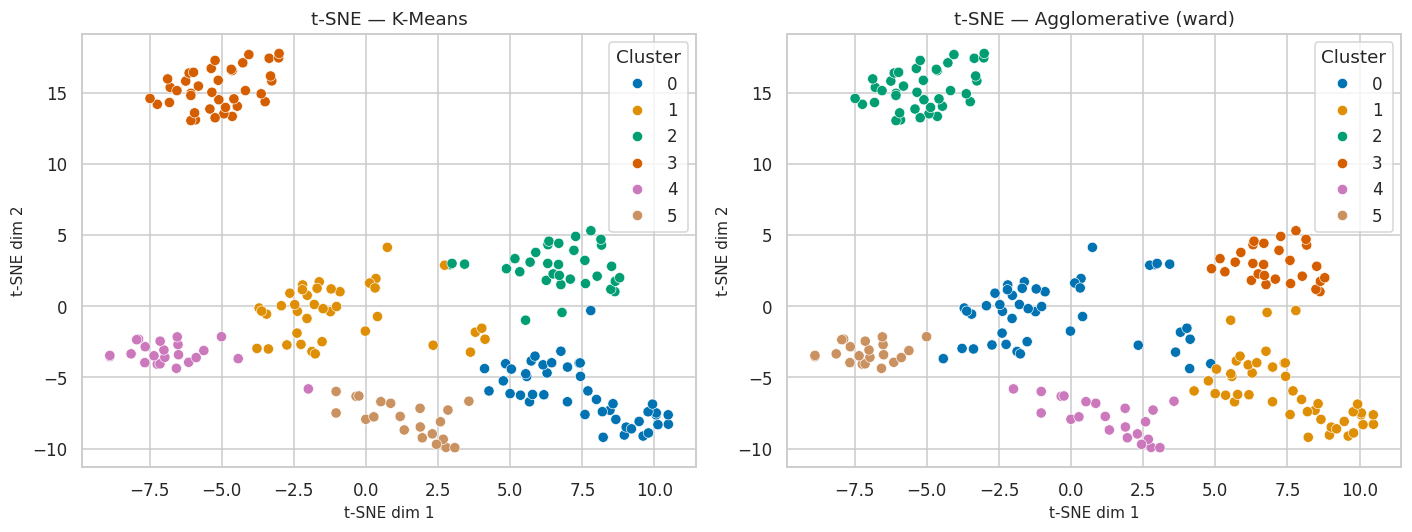

In [9]:
from sklearn.manifold import TSNE
perp = min(30, max(5, (len(Xs) - 1) // 3))
T = TSNE(n_components=2, perplexity=perp, random_state=RANDOM_STATE, init="pca", learning_rate="auto").fit_transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, lab) in zip(axes, labels.items()):
    sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=lab, palette="colorblind", s=45, ax=ax, edgecolor="white", linewidth=0.4, legend="full")
    ax.set_title(f"t-SNE — {name}"); ax.set_xlabel("t-SNE dim 1"); ax.set_ylabel("t-SNE dim 2"); ax.legend(title="Cluster")
plt.tight_layout(); plt.savefig("../figures/clu_tsne.png", bbox_inches="tight"); plt.show()

## 7. Post-hoc interpretation (no ground truth exists)
There is no label to compute ARI/NMI against, so we (a) check how much the two algorithms **agree with each other** (ARI between their labelings) and (b) look at the gender mix of each cluster — gender was *not* used for fitting.

In [10]:
agree_ari = adjusted_rand_score(kmeans.labels_, agg.labels_); agree_nmi = normalized_mutual_info_score(kmeans.labels_, agg.labels_)
val = pd.DataFrame({"K-Means vs Agglomerative": {"Adjusted Rand Index": agree_ari, "Normalized Mutual Info": agree_nmi}}).T
display(val.round(4)); val.round(4).to_csv("../figures/clustering_posthoc_validation.csv")
print("Gender mix per K-Means cluster (row %):")
display((pd.crosstab(pd.Series(kmeans.labels_, name="cluster"), pd.Series(gender, name="gender"), normalize="index")*100).round(1))

,Adjusted Rand Index,Normalized Mutual Info
K-Means vs Agglomerative,0.8914,0.9004


Gender mix per K-Means cluster (row %):


gender,Female,Male
cluster,,
0,57.8,42.2
1,64.1,35.9
2,42.4,57.6
3,53.8,46.2
4,56.5,43.5
5,61.9,38.1


### Cluster profiles (mean of original features per K-Means cluster)

,Age,Annual_Income_k,Spending_Score,size
cluster,,,,
0,56.33,54.27,49.07,45
1,26.79,57.10,48.13,39
2,41.94,88.94,16.97,33
3,32.69,86.54,82.13,39
4,25.00,25.26,77.61,23
5,45.52,26.29,19.38,21


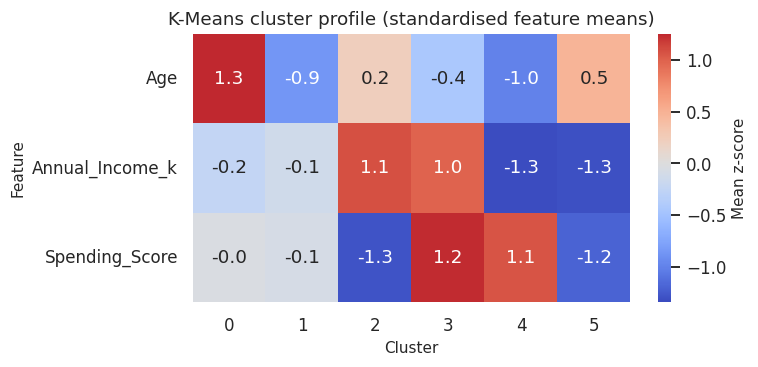

In [11]:
prof = X.assign(cluster=kmeans.labels_).groupby("cluster").mean().round(2); prof["size"] = np.bincount(kmeans.labels_); display(prof)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(pd.DataFrame(Xs, columns=FEATURES).assign(cluster=kmeans.labels_).groupby("cluster").mean().T, cmap="coolwarm", center=0, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "Mean z-score"})
ax.set_title("K-Means cluster profile (standardised feature means)"); ax.set_xlabel("Cluster"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig("../figures/clu_profile.png", bbox_inches="tight"); plt.show()

> ✏️ **DRAFT observation — verify against your plots and rewrite in your own words (course rule 7.5: interpretation must be original).**

There is no ground-truth label, so validation is by agreement and interpretation: K-Means and Ward agree strongly (ARI ≈ 0.89, NMI ≈ 0.90). The profile table gives business-meaningful segments, e.g. **high income / high spending** (cluster 3, avg age ≈ 33 — prime target), **high income / low spending** (cluster 2, ≈ 42 — under-engaged, worth targeting), **low income / high spending** (cluster 4, ≈ 25), **low income / low spending** (cluster 5, ≈ 46), and two mid-income groups separated by age (≈ 27 vs ≈ 56). Gender mix is close to 40–60% in every cluster, so gender is not a segmentation driver.

## 8. Conclusions
_(Write in your own words.)_ Cover: chosen k and why (elbow + silhouette agree/disagree?); which algorithm wins on each metric; effect of linkage; what PCA/t-SNE reveal; agreement between the two algorithms (ARI) and the business meaning of each segment (income vs spending); limitations (scale sensitivity, spherical-cluster assumption of K-Means, O(n²) cost of hierarchical).